In [1]:
# Settings
from pathlib import Path
from functools import lru_cache
import re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
from matplotlib.ticker import MaxNLocator, PercentFormatter
from numpy.polynomial import Polynomial
from scipy.constants import Avogadro, R, pi
from scipy.spatial import ConvexHull
from scipy.spatial.distance import cdist
from scipy.stats import chi2
from IPython.display import display

DATA_FOLDER = Path("Data")
GRID_FOLDER = Path.home() / "MAGEMin_melting"
CONSTANTS_FILE = DATA_FOLDER / "melting_constants.xlsx"
WARREN_FILE = DATA_FOLDER / "Warren.xls"
EXTRA_FOLDER = Path(r"C:\Users\anast\OneDrive\Desktop\abyssal peridotite data")
FIGURE_FOLDER = DATA_FOLDER / "figures" / "Chapter5_DMM_abyssal_REEfit"
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)

SOURCE_REE_COLUMN = "DMM_SS04 (ppm)"
P_MIN_GPA, F_LIMIT, CPX_TOL = 1.0, 0.20, 1e-4
F_INV_GRID = np.round(np.arange(0, 0.2001, 0.0025), 4)

DEGREE = 3
RSD_FLOOR, LOD_SIGMA_PPM = 0.10, 0.005
DATA_MIN_REE = 7
D_CRIT = np.sqrt(chi2.ppf(0.95, DEGREE + 1))
D_BROAD = 6.0
FIT_TIERS = ("Tier 1", "Tier 2", "Outside tiers")
FIT_CUTOFF = {"Tier 1": D_CRIT, "Tier 2": D_BROAD}
FIT_LABEL = {"Tier 1": rf"$D_{{\min}} \leq {D_CRIT:.2f}$",
             "Tier 2": rf"${D_CRIT:.2f} < D_{{\min}} \leq {D_BROAD:g}$",
             "Outside tiers": rf"$D_{{\min}} > {D_BROAD:g}$"}

TIER_GOLD, TIER_SIMS = "LA-ICP-MS", "SIMS"
LITHS = ("Harzburgite", "Lherzolite")
LA_ICPMS_WARREN_REFS = {"Seyler et al 2011", "D'Errico et al 2016"}
LA_ICPMS_SOURCES = {"Harigane et al. (2016)", "Harigane et al. (2022)", "Birner et al. (2021)"}
EXCLUDE_SAMPLES = ["AII96-1-31", "AII96-1-24", "U1382A-9R-1-117-122_core", "KN162-9 D43-85", "KN162-9 D37-13",
                   "Van7-96-37", "Van7-96-29", "PS66:238–2", "PS66:238-24", "PS59:235–123"]
DETAILED_SAMPLES = ["PS66:238-18C", "EDUL-23-2-8"]
EXAMPLES = {"Tier 1": (186, 140, 199), "Tier 2": (139, 147, 109),
            "Outside tiers": (137, 148, 201)}

REE = ["La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu"]
IONIC_RADII = np.array([1.160, 1.143, 1.126, 1.109, 1.079, 1.066, 1.053,
                        1.040, 1.027, 1.015, 1.004, 0.994, 0.985, 0.977])
CI = np.array([0.2414, 0.6194, 0.0939, 0.4737, 0.1536, 0.05883, 0.2069,
               0.03797, 0.2558, 0.05644, 0.1655, 0.02609, 0.1687, 0.02503])
LAMBDA_TERMS = [f"lambda{k}" for k in range(DEGREE + 1)]
PHASES = {"Olivine": "ol_solid", "Orthopyroxene": "opx_solid", "Clinopyroxene": "cpx_solid",
          "Spinel": "spl_solid", "Garnet": "g_solid"}

THESIS_RC = {"font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
             "mathtext.fontset": "stix", "font.size": 10.5, "axes.labelsize": 11.5, "axes.titlesize": 12,
             "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9.5, "figure.facecolor": "white",
             "axes.facecolor": "white", "axes.edgecolor": "0.35", "axes.linewidth": 0.8,
             "xtick.direction": "out", "ytick.direction": "out", "xtick.major.size": 3.5, "ytick.major.size": 3.5}
LITH_COLOUR = {"Harzburgite": "#2C8C9E", "Lherzolite": "#D24D8A"}
GOLD_STUDY_STYLES = {"Seyler et al. (2011)": ("-", "o"), "D'Errico et al. (2016)": ("--", "s"),
                     "Harigane et al. (2016)": ("-.", "^"), "Harigane et al. (2022)": (":", "D"),
                     "Birner et al. (2021)": ((0, (6, 1.5, 1, 1.5, 1, 1.5)), "v")}
DMM_COL = {"fill": "#C9B8D6", "edge": "#7A5F90", "trajectory": "#8B6F9E"}
ACCEPTED_COLOUR = "#e78ac3"
FIT_ALPHA = {"Tier 1": 0.85, "Tier 2": 0.30}
RADIUS_TICKS = [1.15, 1.10, 1.05, 1.00]
LN_LABEL = r"$\ln(\mathrm{Clinopyroxene\ REE}/\mathrm{CI\ chondrite})$"


def save_figure(fig, stem):
    for ext, kw in (("pdf", {}), ("png", {"dpi": 300})):
        fig.savefig(FIGURE_FOLDER / f"{stem}.{ext}", bbox_inches="tight", pad_inches=0.06, **kw)
    plt.show()

In [2]:
# MAGEMin melting paths for DMM
STEM_RE = re.compile(r"^DMM_P(?P<P>\d+(?:p\d+)?)GPa_phi(?P<phi>\d+(?:p\d+)?)wt(?P<tail>.*)\.csv$", re.I)
FILE_KIND = {"_mass_balance": "mass", "_ig": "phase", "_ig_ig": "phase", "": "phase"}
PHASE_GROUPS = {"Olivine": {"ol"}, "Orthopyroxene": {"opx"}, "Clinopyroxene": {"cpx", "pig"},
                "Spinel": {"spl"}, "Garnet": {"g", "grt"}}


def find_pairs(root=GRID_FOLDER):
    found = {}
    for f in sorted(root.rglob("DMM_P*GPa_phi*wt*.csv")):
        m = STEM_RE.match(f.name)
        kind = FILE_KIND.get(m["tail"].lower()) if m else None
        if kind and "partial" not in f.name.lower() and not any("test" in p.lower() for p in f.relative_to(root).parts):
            key = (float(m["P"].replace("p", ".")), float(m["phi"].replace("p", ".")))
            found.setdefault(key, {"mass": [], "phase": []})[kind].append(f)
    pairs = {}
    for key, f in found.items():
        same = [p for p in f["phase"] if f["mass"] and p.parent == f["mass"][0].parent]
        if len(f["mass"]) == 1 and (len(same) == 1 or len(f["phase"]) == 1):
            pairs[key] = ((same or f["phase"])[0], f["mass"][0])
    return pairs


def phase_token(name):
    name = str(name).strip().lower()
    return next((t for t in ("liq", "melt", "fluid", "fl", "cpx", "opx", "spl", "grt", "ol", "pig", "g")
                 if name == t or name.startswith((t + "_", t + "-"))), name)


def load_path(phasefile, massfile):
    mass = pd.read_csv(massfile).sort_values("step").reset_index(drop=True)
    raw = pd.read_csv(phasefile).assign(group=lambda d: d.phase.map(phase_token))
    wide = raw[raw.group != "system"].pivot_table(index="point[#]", columns="group", values="mode[wt%]",
                                                  aggfunc="sum", fill_value=0.0).sort_index() / 100
    out = mass[["T_C", "F_total"]].rename(columns={"F_total": "F"})
    for name, groups in PHASE_GROUPS.items():
        out[PHASES[name]] = (wide.reindex(columns=list(groups), fill_value=0).sum(axis=1).to_numpy(float)
                             / (mass.solid_equilibrium_wt_pct.to_numpy(float) / 100))
    out[list(PHASES.values())] = out[list(PHASES.values())].div(out[list(PHASES.values())].sum(axis=1), axis=0)
    out = out.sort_values("T_C").reset_index(drop=True)
    present = (out.cpx_solid >= CPX_TOL).to_numpy()
    if len(lost := np.flatnonzero(present[:-1] & ~present[1:])):
        out = out.iloc[:lost[0] + 2].reset_index(drop=True)
    keep = [0]
    for i in range(1, len(out)):
        step = out.F[i] - out.F[keep[-1]]
        if step > 1e-10:
            keep.append(i)
        elif abs(step) <= 1e-10:
            keep[-1] = i
    return out.loc[keep].reset_index(drop=True)


MODE_PATHS = {}
for (P, phi_wt), files in sorted(find_pairs().items()):
    if P >= P_MIN_GPA - 1e-9 and len(path := load_path(*files)) >= 2 and path.F.max() > 0:
        MODE_PATHS[P, round(phi_wt / 100, 6)] = path

In [3]:
# Partition coefficients and melting model
constants = pd.read_excel(CONSTANTS_FILE, sheet_name=None)
SOURCE_REE = pd.to_numeric(constants["Sources_REE"].set_index("Element").loc[REE, SOURCE_REE_COLUMN]).to_numpy(float)
D_SPINEL = constants["Partition_Coef"].set_index("REE").loc[REE, "Spinel"].to_numpy(float)


def lattice_strain(D0, E, r0, T_K):
    term = r0 / 2 * (IONIC_RADII - r0) ** 2 + (IONIC_RADII - r0) ** 3 / 3
    return D0 * np.exp(-4 * pi * E * Avogadro / R / T_K * term * 1e-21)


def al_select(spl_coef, grt_coef, k, mode):
    w = mode["Garnet"] / (mode["Spinel"] + mode["Garnet"]) if mode["Spinel"] + mode["Garnet"] > 0 else 0.0
    return (1 - w) * (np.array(spl_coef) @ k) + w * (np.array(grt_coef) @ k)


def D_ree_variable(P, T_K, F, mode):
    k = np.kron([F, 1.0], [T_K, 1.0])
    D = {"Spinel": D_SPINEL}
    X_Al = al_select([-1.166e-4, 1.628e-1, 6.632e-5, -1.001e-1], [4.717e-6, -7.203e-3, -2.738e-6, 1.069e-2], k, mode)
    Mg_num = al_select([4.746e-5, -2.941e-2, 4.057e-6, 8.990e-1], [-6.102e-7, 6.992e-2, 1.893e-5, 8.604e-1], k, mode)
    D["Olivine"] = lattice_strain(np.exp(-0.44 - 0.18 * P + 123.75 * X_Al - 1.49 * Mg_num), 298.0, 0.809, T_K)
    X_Al_T = al_select([-8.137e-4, 1.060, 1.786e-4, -1.333e-1], [1.070e-3, -2.114, -5.671e-4, 1.196], k, mode)
    X_Ca_M2 = al_select([-1.097e-3, 1.747, 2.037e-4, -2.385e-1], [-1.862e-4, 2.338e-1, 1.426e-4, -1.559e-1], k, mode)
    X_Mg_M2 = al_select([1.274e-3, -1.969, -2.631e-4, 1.242], [1.386e-4, -6.299e-2, -1.497e-4, 1.063], k, mode)
    X_Ti = al_select([2.087e-4, -4.405e-1, 1.498e-5, 1.156e-2], [1.225e-4, -3.037e-1, -2.206e-5, 8.261e-2], k, mode)
    r0 = 0.693 + 0.432 * X_Ca_M2 + 0.228 * X_Mg_M2
    D["Orthopyroxene"] = lattice_strain(np.exp(-5.37 + 3.87e4 / (R * T_K) + 3.54 * X_Al_T + 3.56 * X_Ca_M2 - 0.84 * X_Ti),
                                        (1.85 * r0 - 1.37 - 0.53 * X_Ca_M2) * 1e3, r0, T_K)
    X_Mg_M2 = al_select([3.000e-3, -4.675, 1.270e-3, -1.688], [-5.157e-6, 2.422e-1, 2.201e-4, 1.312e-1], k, mode)
    X_Al2O3 = al_select([3.055e-4, -6.387e-1, -1.313e-4, 3.259e-1], [1.264e-4, -2.287e-1, -1.855e-4, 4.052e-1], k, mode)
    X_SiO2 = al_select([5.050e-4, -8.057e-1, -3.469e-4, 1.065], [8.899e-8, 2.692e-2, -1.265e-4, 6.800e-1], k, mode)
    melt_factor = X_SiO2 ** 2.54 * 2 * X_Al2O3 / X_SiO2 * 1.99
    D["Clinopyroxene"] = lattice_strain(np.exp(-2.07 + 0.52e4 / T_K), 238.0, 1.036 - 0.08 * X_Mg_M2, T_K) * melt_factor
    X_Ca = np.array([4.516e-5, -2.685e-1, -2.325e-4, 7.989e-1]) @ k
    r0 = 0.785 + 0.153 * X_Ca
    D["Garnet"] = lattice_strain(np.exp(-2.01 + (9.03e4 - 93.02 * P * (37.78 - P)) / (R * T_K) - 1.04 * X_Ca),
                                 (-1.67 + 2.35 * r0) * 1e3, r0, T_K)
    return D


@lru_cache(maxsize=None)
def mode_at(P, phi, F):
    path = MODE_PATHS[P, phi]
    if F > path.F.max() + 1e-10:
        return None
    return {name: float(np.interp(F, path.F, path[col])) for name, col in PHASES.items()}


def T_at(P, phi, F):
    return float(np.interp(F, MODE_PATHS[P, phi].F, MODE_PATHS[P, phi].T_C)) + 273.15


@lru_cache(maxsize=None)
def D_at(P, phi, F):
    return D_ree_variable(P, T_at(P, phi, F), F, mode_at(P, phi, F) or mode_at(P, phi, 0.0))


def bulk_D(mode, D):
    return sum(mode[ph] * D[ph] for ph in PHASES)


def residue_step(D0, Pr, f, phi):
    D_eff, P_eff = phi + (1 - phi) * D0, phi + (1 - phi) * Pr
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        base = 1 - P_eff * f / D_eff
        ratio = np.where(np.abs(P_eff) < 1e-12, np.exp(-f / D_eff), np.power(base, 1 / P_eff)) / (1 - f)
    return np.where((D_eff > 0) & (base > 0) & np.isfinite(ratio), ratio, np.nan)


def cpx_ratio(P, phi, F):
    path, mode_F = MODE_PATHS[P, phi], mode_at(P, phi, F)
    if mode_F is None or mode_F["Clinopyroxene"] < CPX_TOL:
        return np.full(len(REE), np.nan)
    D_F = D_at(P, phi, F)
    if F <= phi:
        return D_F["Clinopyroxene"] / (F + (1 - F) * bulk_D(mode_F, D_F))
    points = [phi] + path.loc[(path.F > phi) & (path.F < F), "F"].tolist() + [F]
    ratio = np.ones(len(REE))
    for F0, F1 in zip(points[:-1], points[1:]):
        m0, m1 = mode_at(P, phi, float(F0)), mode_at(P, phi, float(F1))
        if m0 is None or m1 is None or m1["Clinopyroxene"] < CPX_TOL:
            return np.full(len(REE), np.nan)
        f = (F1 - F0) / (1 - F0)
        reacting = {ph: (m0[ph] - (1 - f) * m1[ph]) / f for ph in PHASES}
        D_k = D_at(P, phi, float(F0))
        ratio *= residue_step(bulk_D(m0, D_k), bulk_D(reacting, D_k), f, phi)
        if not np.isfinite(ratio).all():
            return np.full(len(REE), np.nan)
    return D_F["Clinopyroxene"] * ratio / (phi + (1 - phi) * bulk_D(mode_F, D_F))

In [4]:
# Model library
def ree_polynomials(radii=IONIC_RADII, degree=DEGREE):
    polys = []
    for n in range(degree + 1):
        p = Polynomial([0] * n + [1])
        for q in polys:
            p = p - (np.sum(p(radii) * q(radii)) / np.sum(q(radii) ** 2)) * q
        polys.append(p / p.coef[-1])
    return polys


REE_POLYNOMIALS = ree_polynomials()


def full_ree_basis(r):
    return np.column_stack([p(np.asarray(r, float)) for p in REE_POLYNOMIALS])


def ln_ci(ppm):
    ppm = np.asarray(ppm, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(ppm > 0, np.log(ppm / CI), np.nan)


A_ALL = full_ree_basis(IONIC_RADII)


def library_lambda(ppm):
    return np.linalg.lstsq(A_ALL, ln_ci(ppm), rcond=None)[0]


def build_library():
    rows = []
    for P, phi in sorted(MODE_PATHS):
        for f in F_INV_GRID[F_INV_GRID <= min(F_LIMIT, MODE_PATHS[P, phi].F.max()) + 1e-10]:
            v = cpx_ratio(P, phi, float(f)) * SOURCE_REE
            if np.isfinite(v).all() and (v > 0).all():
                rows.append({"P_GPa": P, "Phi": phi, "F": float(f), **dict(zip(REE, v)),
                             **dict(zip(LAMBDA_TERMS, library_lambda(v)))})
    return pd.DataFrame(rows)


grid_library = build_library()
LIB_LNY = ln_ci(grid_library[REE].to_numpy(float))
PARAMS = grid_library[["P_GPa", "Phi", "F"]].to_numpy(float)
print(f"Library: {len(grid_library):,} patterns from {grid_library.groupby(['P_GPa', 'Phi']).ngroups} paths | "
      f"P {grid_library.P_GPa.min():g}-{grid_library.P_GPa.max():g} GPa, Phi {100 * grid_library.Phi.min():g}-"
      f"{100 * grid_library.Phi.max():g} wt%, F max {100 * grid_library.F.max():g}% | paths ending before F = 20%: "
      f"{(grid_library.groupby(['P_GPa', 'Phi']).F.max() < F_LIMIT - 1e-9).sum()}")

Library: 50,313 patterns from 651 paths | P 1-2 GPa, Phi 0-3 wt%, F max 19.5% | paths ending before F = 20%: 651


In [5]:
# Abyssal peridotite clinopyroxene data
def read_input(path, **kw):
    frame = pd.read_excel(path, **kw)
    frame.columns = frame.columns.astype(str).str.strip()
    return frame


def numeric_ree(frame, scale=1.0):
    frame = frame.copy()
    for e in REE:
        frame[e] = pd.to_numeric(frame[e], errors="coerce") * scale if e in frame else np.nan
    return frame


def norm_name(name):
    return re.sub(r"[‐-―−]", "-", str(name)).strip()


w16 = read_input(WARREN_FILE, sheet_name="AllPhasesRes", header=1)
w16 = w16[(pd.to_numeric(w16.Type, errors="coerce") == 1) & (w16.Sample.astype(str).str.strip() != "DMM-WH05")]
w16 = numeric_ree(w16.assign(
    lithology_group=w16.Lithology.astype(str).str.strip().map({"Harz": "Harzburgite", "Lherz": "Lherzolite"}),
    Source="Warren (2016)",
    Study=w16["Cpx Trace Ref"].astype(str).str.strip().str.replace(r"\bet al\b\.?", "et al.", regex=True)
          .str.replace(r" (\d{4}[a-z]?)\b", r" (\1)", regex=True)))

h16 = read_input(EXTRA_FOLDER / "Harigane2016.xlsx")
h16["Sample No."] = h16["Sample No."].ffill()
part = h16.Clinopyroxene.astype(str).str.strip().str.lower()
h16 = numeric_ree(h16[part.isin(["core", "rim"])].assign(
    Sample=h16["Sample No."].astype(str).str.strip() + "_" + part, lithology_group="Harzburgite",
    Source="Harigane et al. (2016)"), scale=1e-3)

h22 = read_input(EXTRA_FOLDER / "Harigane2022.xlsx")
h22 = numeric_ree(h22[h22.Lithology.isin(LITHS)].assign(
    Sample=h22.Sample.astype(str).str.strip(), lithology_group=h22.Lithology, Source="Harigane et al. (2022)"))

b21 = read_input(EXTRA_FOLDER / "Birner2021.xlsx", sheet_name="Trace elements", header=3)
opx_rows = np.flatnonzero(b21["Unnamed: 0"].astype(str).str.strip().str.lower().eq("orthopyroxene"))
b21 = b21.iloc[:opx_rows[0] if len(opx_rows) else len(b21)]
b21 = b21[b21["sample"].notna()].rename(columns={"sample": "Sample", "Gd(Dy)": "Gd"})
b21 = numeric_ree(b21.assign(Sample=b21.Sample.astype(str).str.strip(), lithology_group="Lherzolite",
                             Source="Birner et al. (2021)"))
for frame in (h16, h22, b21):
    frame["Study"] = frame.Source

warren_all = pd.concat([w16, h16, h22, b21], ignore_index=True, sort=False)
warren_all[REE] = warren_all[REE].where(warren_all[REE] > 0)
warren_all = warren_all[warren_all.lithology_group.notna()
                        & warren_all[REE].notna().sum(axis=1).ge(DATA_MIN_REE)].reset_index(drop=True)
warren_all["analysis_id"] = np.arange(len(warren_all))
warren_all["trace_method"] = np.where(warren_all.Source.isin(LA_ICPMS_SOURCES) |
                                      warren_all["Cpx Trace Ref"].astype(str).str.strip().isin(LA_ICPMS_WARREN_REFS),
                                      TIER_GOLD, TIER_SIMS)
warren_all["included"] = ~warren_all.Sample.map(norm_name).isin({norm_name(s) for s in EXCLUDE_SAMPLES})
warren = warren_all[warren_all.included & warren_all.trace_method.eq(TIER_GOLD)].reset_index(drop=True)
print(f"Excluded LA-ICP-MS analyses: {(~warren_all.included & warren_all.trace_method.eq(TIER_GOLD)).sum()}")
display(pd.crosstab(warren.Study, warren.lithology_group, margins=True))

Excluded LA-ICP-MS analyses: 6


C:\Users\anast\anaconda3\envs\masters\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


lithology_group,Harzburgite,Lherzolite,All
Study,,,
Birner et al. (2021),0,11,11
D'Errico et al. (2016),3,5,8
Harigane et al. (2016),6,0,6
Harigane et al. (2022),3,4,7
Seyler et al. (2011),13,6,19
All,25,26,51


In [6]:
# Lambda fits and grid-search inversion
def sigma_ln(ppm):
    return np.sqrt((RSD_FLOOR * ppm) ** 2 + LOD_SIGMA_PPM ** 2) / ppm


def fit_lambda(ppm):
    good = np.isfinite(ppm) & (ppm > 0)
    y, sigma = ln_ci(ppm)[good], sigma_ln(ppm[good])
    Aw = full_ree_basis(IONIC_RADII[good]) / sigma[:, None]
    return dict(lambdas=np.linalg.lstsq(Aw, y / sigma, rcond=None)[0], cov=np.linalg.pinv(Aw.T @ Aw),
                good=good, gain=np.linalg.pinv(Aw) / sigma)


FITS = {aid: fit_lambda(ppm) for aid, ppm in zip(warren.analysis_id, warren[REE].to_numpy(float))}
warren[LAMBDA_TERMS] = np.array([f["lambdas"] for f in FITS.values()])


def projected_lambda(aid):
    return LIB_LNY[:, FITS[aid]["good"]] @ FITS[aid]["gain"].T


def mahalanobis(aid):
    f = FITS[aid]
    sd = np.sqrt(np.diag(f["cov"]))
    corr = f["cov"] / np.outer(sd, sd)
    VI = np.linalg.inv((corr + corr.T) / 2) / np.outer(sd, sd)
    return cdist(projected_lambda(aid), f["lambdas"][None, :], "mahalanobis", VI=VI).ravel()


def fit_tier(d):
    return next((t for t, cut in FIT_CUTOFF.items() if d <= cut), FIT_TIERS[-1])


results, accepted = [], []
for s in warren.itertuples():
    D = mahalanobis(s.analysis_id)
    best = int(np.argmin(D))
    tier = fit_tier(D[best])
    results.append({"analysis_id": s.analysis_id, "Sample": s.Sample, "Lithology": s.lithology_group, "Study": s.Study,
                    "D_min": D[best], "fit_tier": tier, "best_model": best,
                    **dict(zip(["P_best", "Phi_best", "F_best"], PARAMS[best]))})
    if tier in FIT_CUTOFF:
        acc = np.flatnonzero(D <= FIT_CUTOFF[tier])
        accepted.append(pd.DataFrame({"analysis_id": s.analysis_id, "fit_tier": tier, "Lithology": s.lithology_group,
                                      "model": acc, "D": D[acc], **dict(zip(["P", "Phi", "F"], PARAMS[acc].T)),
                                      "weight": 1 / len(acc)}))
pop_res, hist_models = pd.DataFrame(results), pd.concat(accepted, ignore_index=True)
display(pd.crosstab(pop_res.Lithology, pd.Categorical(pop_res.fit_tier, categories=FIT_TIERS), rownames=["Lithology"],
                    colnames=["Fit tier"], margins=True, dropna=False))

Fit tier,Tier 1,Tier 2,Outside tiers,All
Lithology,,,,
Harzburgite,5,7,13,25
Lherzolite,6,3,17,26
All,11,10,30,51


In [7]:
# Plot helpers
def lambda_curve(lam, n=250):
    x = np.linspace(IONIC_RADII.min(), IONIC_RADII.max(), n)
    return x, full_ree_basis(x) @ np.asarray(lam, float)


def limits(*arrays, pad=0.08, min_span=0.0):
    v = np.concatenate([np.ravel(np.asarray(a, float)) for a in arrays])
    v = v[np.isfinite(v)]
    span = max(np.ptp(v), min_span) or 1.0
    return v.min() - pad * span, v.max() + pad * span


def add_ree_top_axis(ax, fontsize=9, low_offset=4, high_offset=13):
    top = ax.secondary_xaxis("top")
    top.set_xticks(IONIC_RADII, labels=[])
    top.tick_params(direction="out", pad=0, length=3.0, width=0.8)
    top.spines["top"].set_color("0.35")
    for n, (el, radius) in enumerate(zip(REE, IONIC_RADII)):
        ax.annotate(el, (radius, 1.0), xycoords=("data", "axes fraction"), ha="center", va="bottom", fontsize=fontsize,
                    xytext=(0, low_offset if n % 2 == 0 else high_offset), textcoords="offset points")


def style_ree_axis(ax):
    ax.set_xlim(IONIC_RADII.max() + 0.005, IONIC_RADII.min() - 0.005)
    ax.set_xticks(RADIUS_TICKS)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("0.35")
    ax.grid(False)

ROCK_MARKERS = {"Harzburgite": "o", "Lherzolite": "^"}

def scatter_natural(ax, x, y):
    for l in LITHS:
        d = warren[warren.lithology_group == l]
        ax.scatter(d[x], d[y], s=46, marker=ROCK_MARKERS[l], color=LITH_COLOUR[l], alpha=0.95,
                   edgecolors="0.15", linewidths=0.35, zorder=5)

def natural_handles():
    return [Line2D([], [], ls="none", marker=ROCK_MARKERS[l], markersize=8, markeredgecolor="0.15",
                   markerfacecolor=LITH_COLOUR[l], label=f"{l}, LA-ICP-MS (n={(warren.lithology_group == l).sum()})")
            for l in LITHS]

In [8]:
# Analytical uncertainty ellipse
import json
from matplotlib.patches import Ellipse

UNC_FILE = Path.home() / "Anastasia_Morfiadakis_MESA" / "Data" / "ch3_lambda_uncertainty.json"
LAMBDA_UNC = json.loads(UNC_FILE.read_text())
UNC_COV, UNC_K = np.array(LAMBDA_UNC["cov_total"]), LAMBDA_UNC["k95"]
UNC_COLOUR = "0.15"
UNC_HANDLE = Line2D([], [], ls="", marker="o", ms=10, mfc="none", mec=UNC_COLOUR, mew=1.6,
                    label="Analytical uncertainty (95%)")
CORNERS = ("lower left", "lower right", "upper left", "upper right")


def add_unc_ellipse(ax, i, j, x=None, y=None, avoid=(), pad=0.05):
    cov = UNC_COV[np.ix_([i, j], [i, j])]
    vals, vecs = np.linalg.eigh(cov)
    vals, vecs = np.clip(vals[::-1], 0, None), vecs[:, ::-1]
    half = UNC_K * np.sqrt(np.diag(cov))
    (xa, xb), (ya, yb) = sorted(ax.get_xlim()), sorted(ax.get_ylim())
    gap = pad * np.array([xb - xa, yb - ya])
    centres = {"lower left": (xa + gap[0] + half[0], ya + gap[1] + half[1]),
               "lower right": (xb - gap[0] - half[0], ya + gap[1] + half[1]),
               "upper left": (xa + gap[0] + half[0], yb - gap[1] - half[1]),
               "upper right": (xb - gap[0] - half[0], yb - gap[1] - half[1])}
    px = np.asarray(x if x is not None else [], float)
    py = np.asarray(y if y is not None else [], float)
    crowd = {c: np.sum((np.abs(px - cx) <= half[0] + gap[0]) & (np.abs(py - cy) <= half[1] + gap[1]))
             for c, (cx, cy) in centres.items() if c not in avoid}
    best = min(crowd, key=lambda c: (crowd[c], CORNERS.index(c)))
    ax.add_patch(Ellipse(centres[best], 2 * UNC_K * np.sqrt(vals[0]), 2 * UNC_K * np.sqrt(vals[1]),
                         angle=np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0])), facecolor="none", edgecolor=UNC_COLOUR,
                         lw=1.6, zorder=8, path_effects=[pe.Stroke(linewidth=3.6, foreground="white"), pe.Normal()]))
    return best

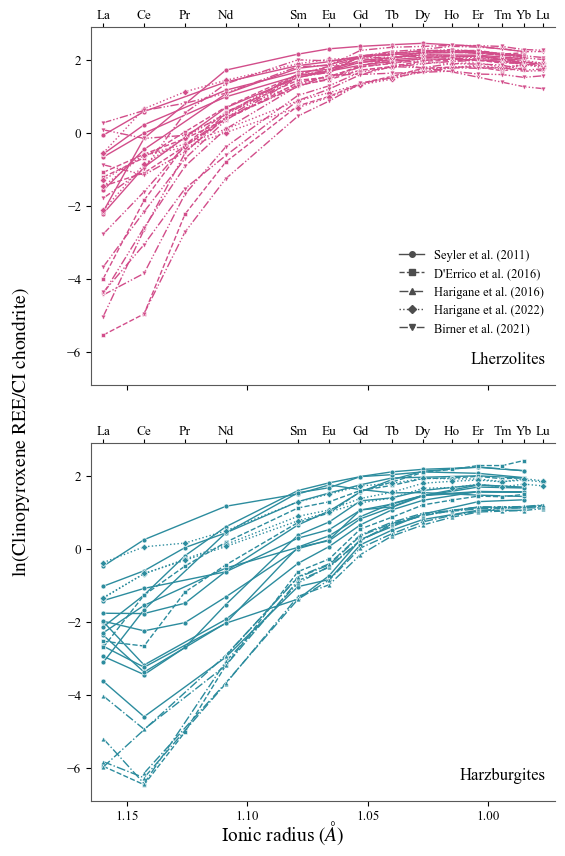

In [9]:
# Figure 5.1
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(2, 1, figsize=(5.8, 9.0), sharex=True, sharey=True)
    for ax, lith in zip(axes, ("Lherzolite", "Harzburgite")):
        group = warren[warren.lithology_group == lith]
        for study, rows in group.groupby("Study", sort=False):
            ls, mk = GOLD_STUDY_STYLES[study]
            for y in ln_ci(rows[REE].to_numpy(float)):
                ax.plot(IONIC_RADII[np.isfinite(y)], y[np.isfinite(y)], color=LITH_COLOUR[lith], ls=ls, lw=1.0, marker=mk,
                        ms=3.5, mfc=LITH_COLOUR[lith], mec="white", mew=0.4, zorder=3)
        style_ree_axis(ax)
        top = ax.secondary_xaxis("top")
        top.set_xticks(IONIC_RADII, labels=REE, fontsize=9.5)
        top.tick_params(length=3, pad=1)
        ax.text(0.98, 0.05, f"{lith}s", transform=ax.transAxes, ha="right", va="bottom", fontsize=12)
    handles = [Line2D([], [], color="0.3", ls=ls, marker=mk, ms=4, lw=1, label=study)
               for study, (ls, mk) in GOLD_STUDY_STYLES.items() if (warren.Study == study).any()]
    axes[0].legend(handles=handles, frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.11), fontsize=9)
    fig.supylabel(LN_LABEL, x=0.03, fontsize=14)
    fig.supxlabel(r"Ionic radius ($\AA$)", y=0.04, fontsize=14)
    fig.subplots_adjust(left=0.17, right=0.97, bottom=0.09, top=0.95, hspace=0.16)
    save_figure(fig, "abyssal_cpx_spiders_lherz_harz_vertical_DMM")

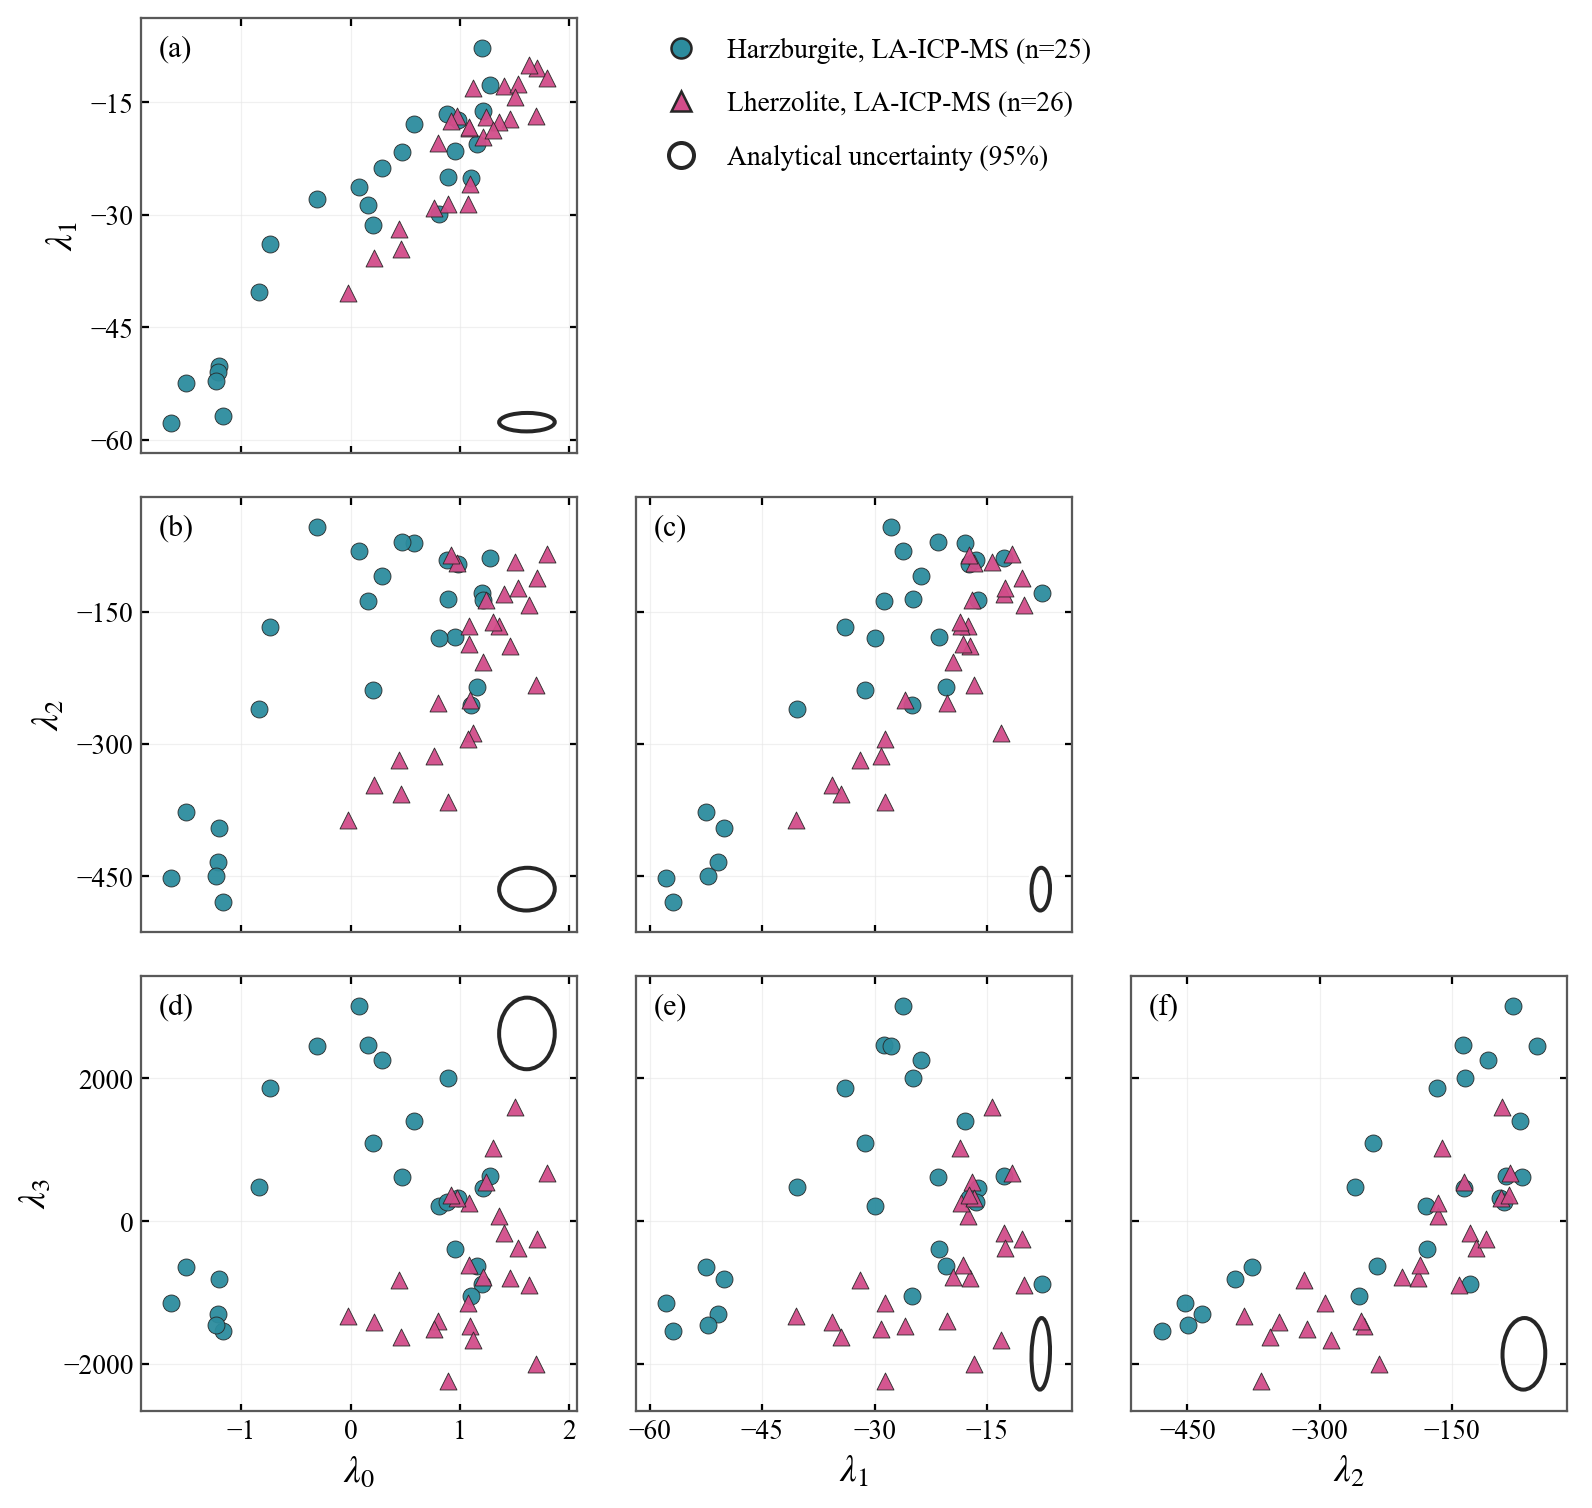

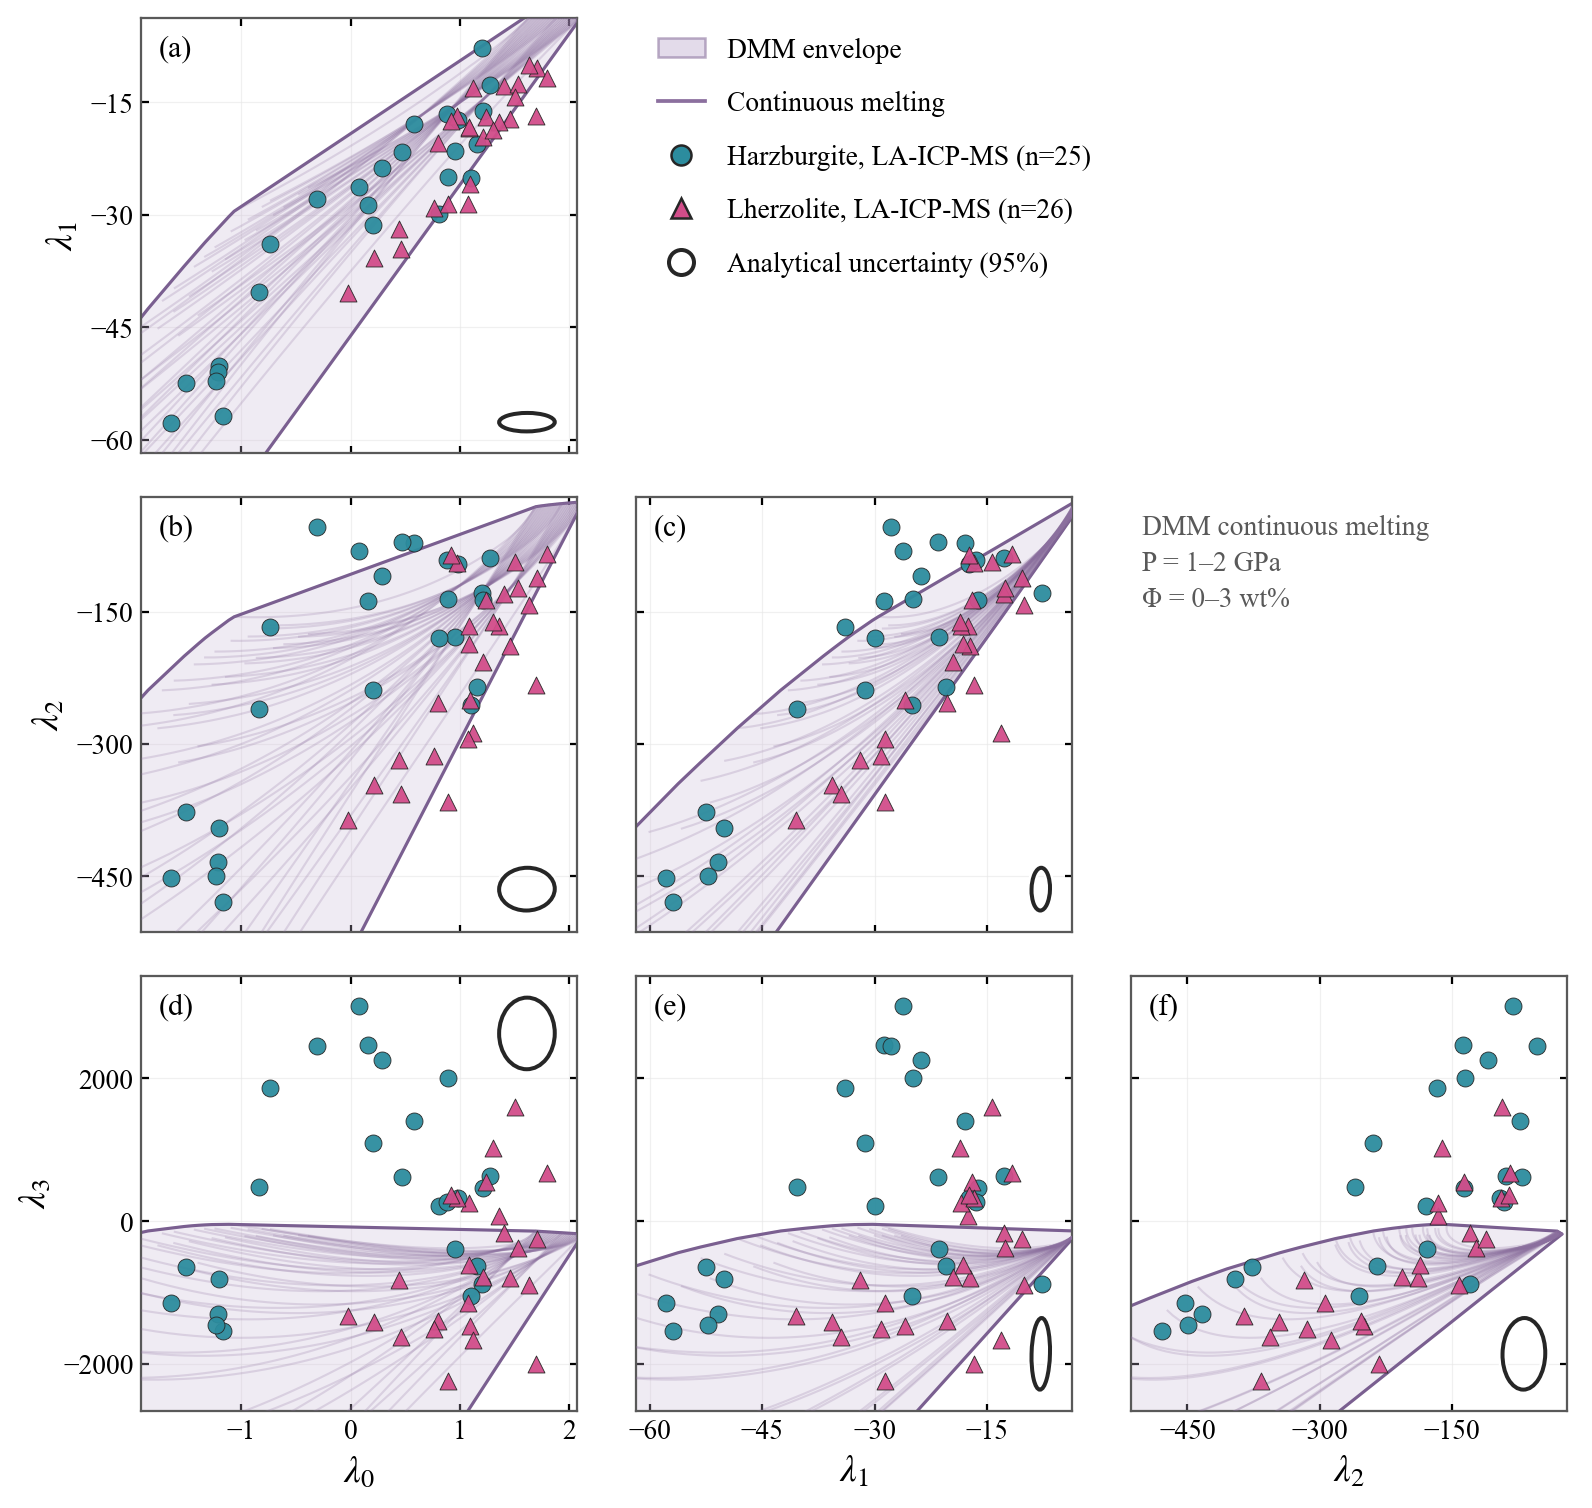

Inside the envelope in all three lambda0-lambda2 projections: 31 of 51; in all six: 18


In [10]:
# Figures 5.2 and 5.7
def corner(stem, models=False, n_paths=45):
    inside = {}
    if models:
        paths = [g.sort_values("F") for _, g in grid_library.groupby(["P_GPa", "Phi"]) if len(g) >= 2]
        paths = [paths[k] for k in np.linspace(0, len(paths) - 1, min(n_paths, len(paths))).astype(int)]
    with plt.rc_context({**THESIS_RC, "font.size": 12, "xtick.labelsize": 11, "ytick.labelsize": 11}):
        fig, axes = plt.subplots(3, 3, figsize=(9.2, 8.9), dpi=180)
        fig.subplots_adjust(left=0.11, right=0.98, bottom=0.10, top=0.97, wspace=0.10, hspace=0.10)
        for i, j in np.ndindex(3, 3):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            x, y = LAMBDA_TERMS[j], LAMBDA_TERMS[i + 1]
            if models:
                xy = np.unique(grid_library[[x, y]].to_numpy(float), axis=0)
                hull = ConvexHull(xy)
                v = xy[hull.vertices]
                ax.fill(*v.T, color=DMM_COL["fill"], alpha=0.28, zorder=1)
                ax.plot(*np.r_[v, v[:1]].T, color=DMM_COL["edge"], lw=1.25, zorder=2)
                inside[f"{x}__{y}"] = np.all(warren[[x, y]].to_numpy(float) @ hull.equations[:, :2].T
                                             + hull.equations[:, 2] <= 1e-9, axis=1)
                for p in paths:
                    ax.plot(p[x], p[y], color=DMM_COL["trajectory"], alpha=0.22, lw=0.85, zorder=3)
            scatter_natural(ax, x, y)
            ax.set(xlim=limits(warren[x]), ylim=limits(warren[y]))
            add_unc_ellipse(ax, j, i + 1, warren[x], warren[y], avoid=("upper left",))
            ax.set_box_aspect(1)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.tick_params(direction="in", top=True, right=True, length=3, width=0.9, pad=3, labelsize=11,
                           labelbottom=i == 2, labelleft=j == 0)
            if i == 2:
                ax.set_xlabel(rf"$\lambda_{j}$", fontsize=15)
            if j == 0:
                ax.set_ylabel(rf"$\lambda_{i + 1}$", fontsize=15)
            ax.text(0.04, 0.96, f"({string.ascii_lowercase[i * (i + 1) // 2 + j]})", transform=ax.transAxes, va="top",
                    fontsize=12, zorder=10, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2))
            ax.set_axisbelow(True)
            ax.grid(color="0.90", linewidth=0.5, alpha=0.6)
            for spine in ax.spines.values():
                spine.set(color="0.35", linewidth=0.9)
        handles = natural_handles() + [UNC_HANDLE]
        if models:
            handles = [Patch(facecolor=DMM_COL["fill"], edgecolor=DMM_COL["edge"], alpha=0.5, label="DMM envelope"),
                       Line2D([], [], color=DMM_COL["trajectory"], lw=1.5, label="Continuous melting")] + handles
            axes[1, 2].text(0.04, 0.96, f"DMM continuous melting\nP = {grid_library.P_GPa.min():g}–"
                            f"{grid_library.P_GPa.max():g} GPa\nΦ = {100 * grid_library.Phi.min():g}–"
                            f"{100 * grid_library.Phi.max():g} wt%", transform=axes[1, 2].transAxes, va="top",
                            fontsize=11, color="0.35", linespacing=1.5)
        axes[0, 1].legend(handles=handles, loc="upper left", bbox_to_anchor=(0.04, 0.98), frameon=False, fontsize=11,
                          handlelength=1.7, labelspacing=1.0, borderaxespad=0)
        save_figure(fig, stem)
    return pd.DataFrame(inside)


corner("lambda_abyssal_natural_only_l0_l3_DMM")
inside = corner("lambda_abyssal_continuous_trajectories_DMM_corner", models=True)
low = inside[[c for c in inside if "lambda3" not in c]].all(axis=1)
print(f"Inside the envelope in all three lambda0-lambda2 projections: {low.sum()} of {len(inside)}; "
      f"in all six: {inside.all(axis=1).sum()}")

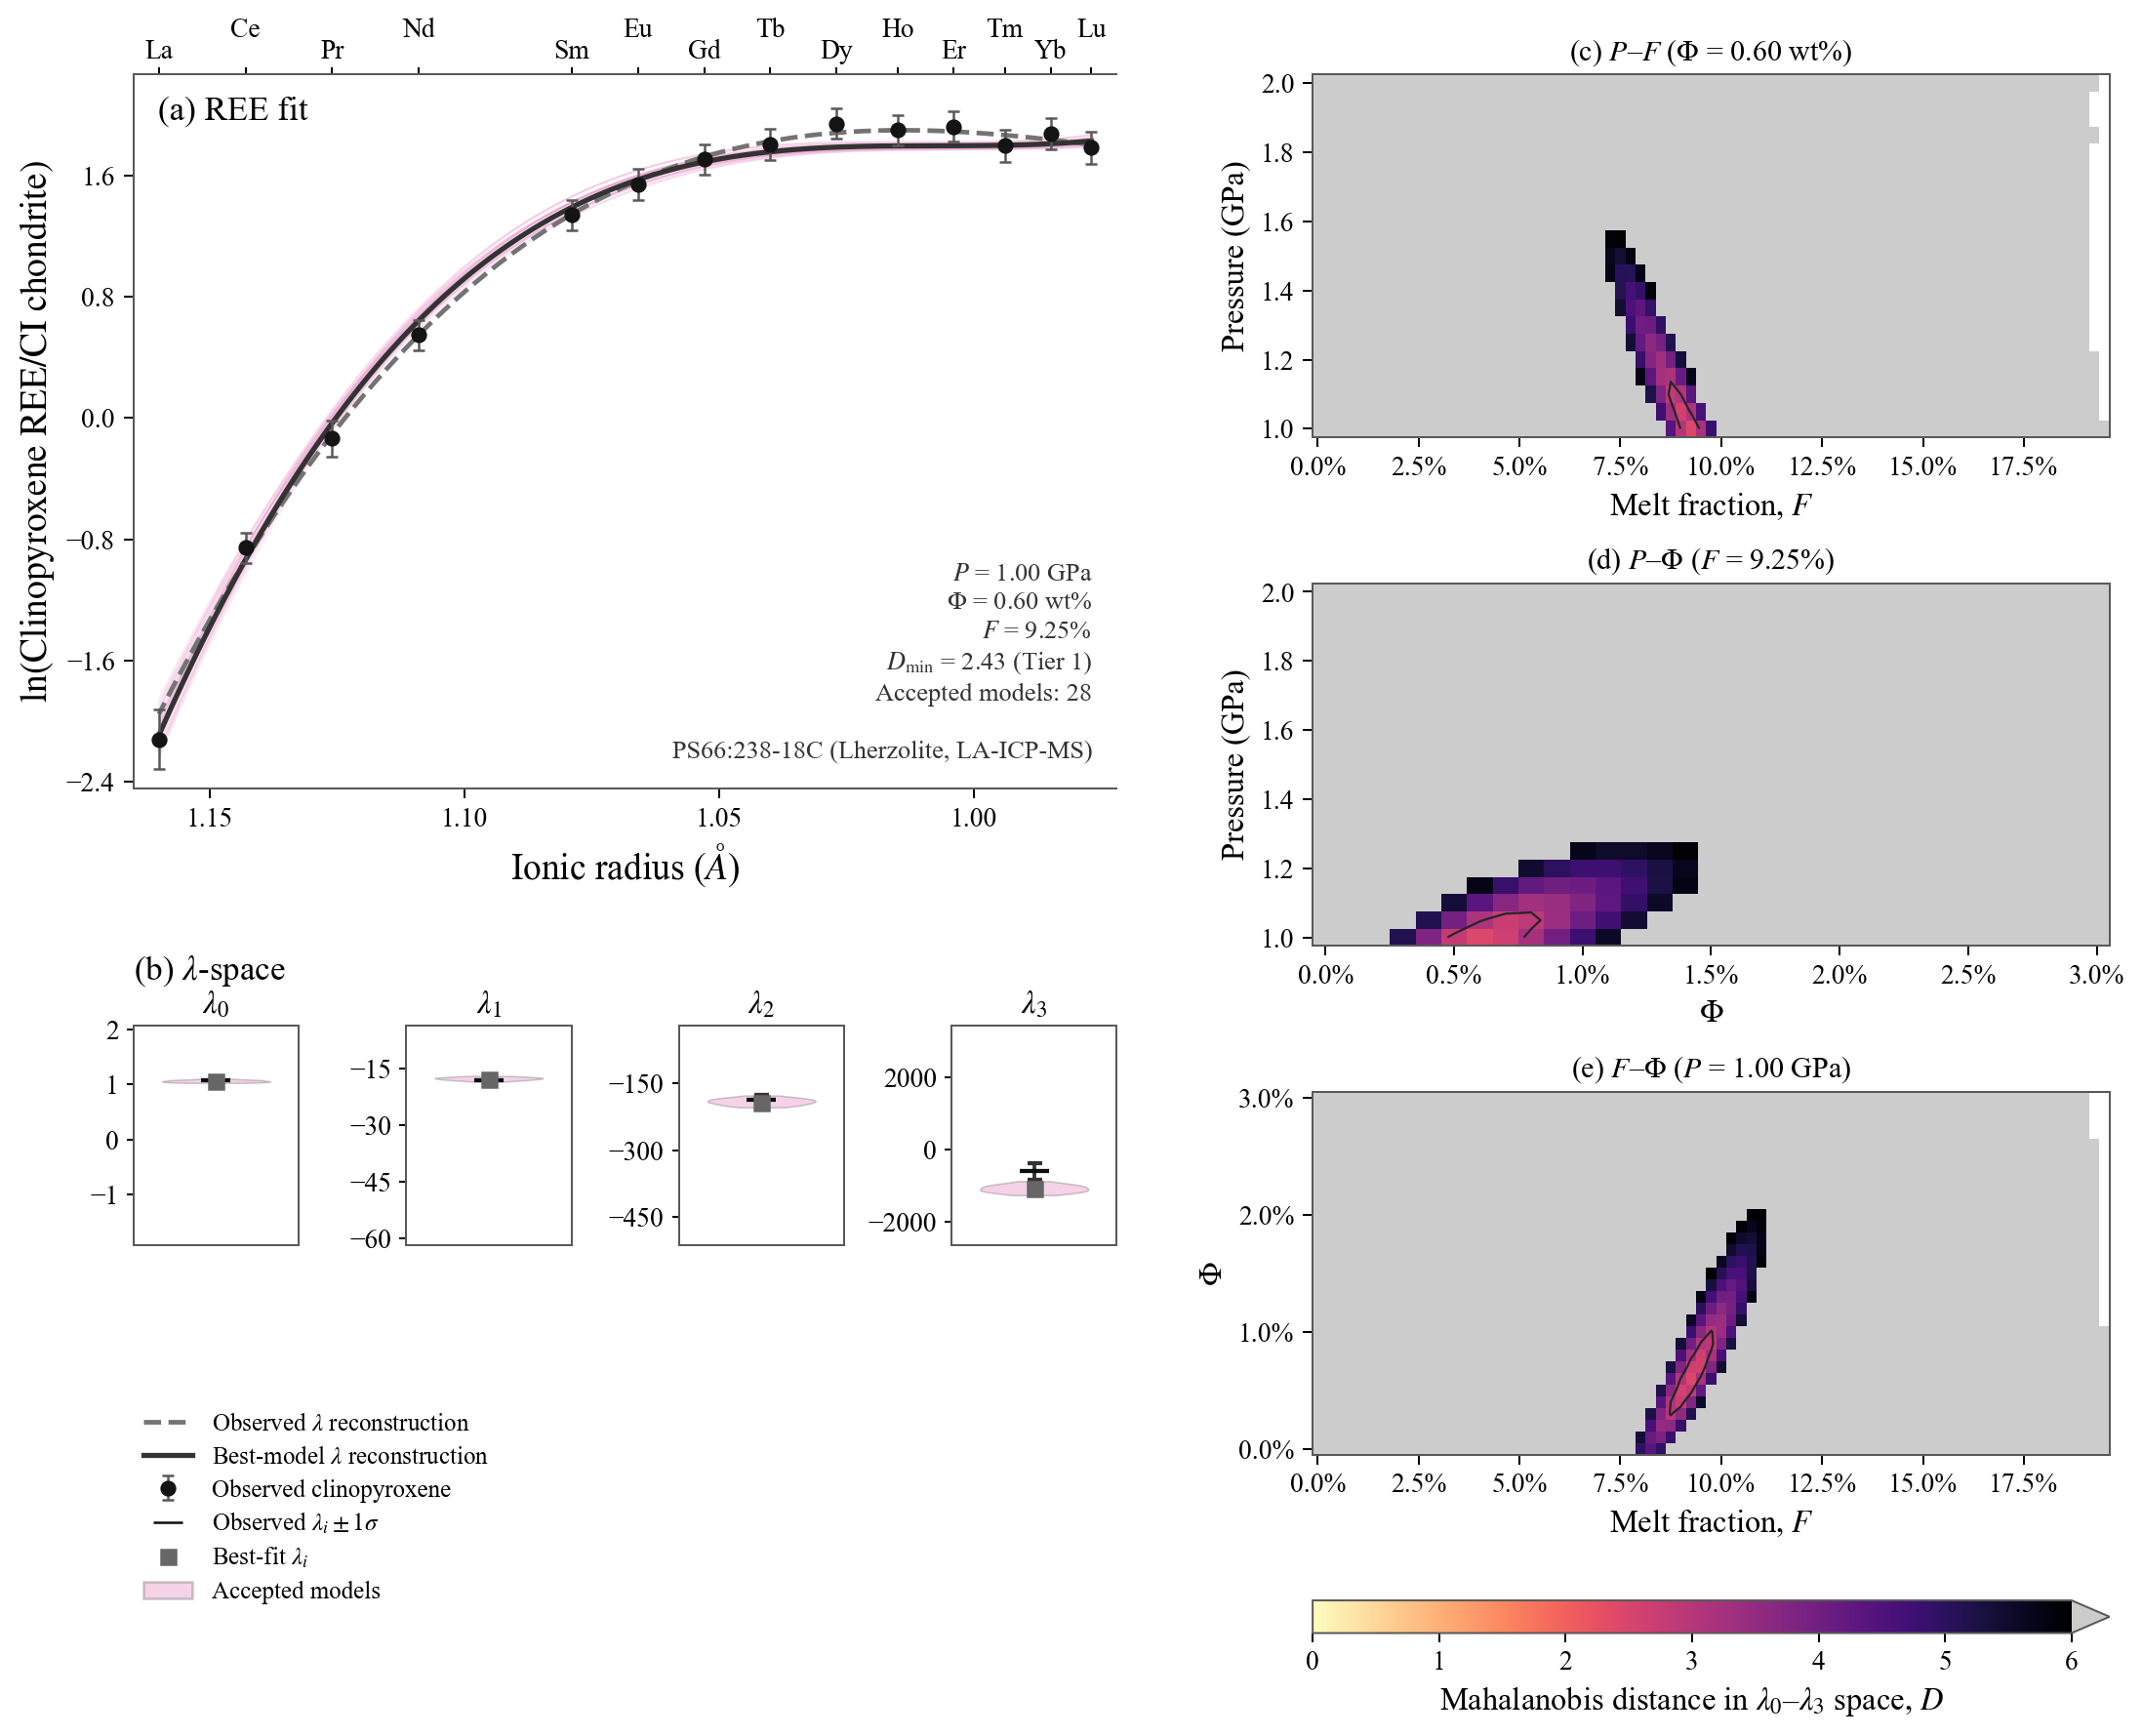

PS66:238-18C: P = 1.00 GPa, Phi = 0.60 wt%, F = 9.25%, D_min = 2.43 (Tier 1) | 28 accepted models: P 1.00-1.15 GPa, Phi 0.3-1.0 wt%, F 8.25-9.75%


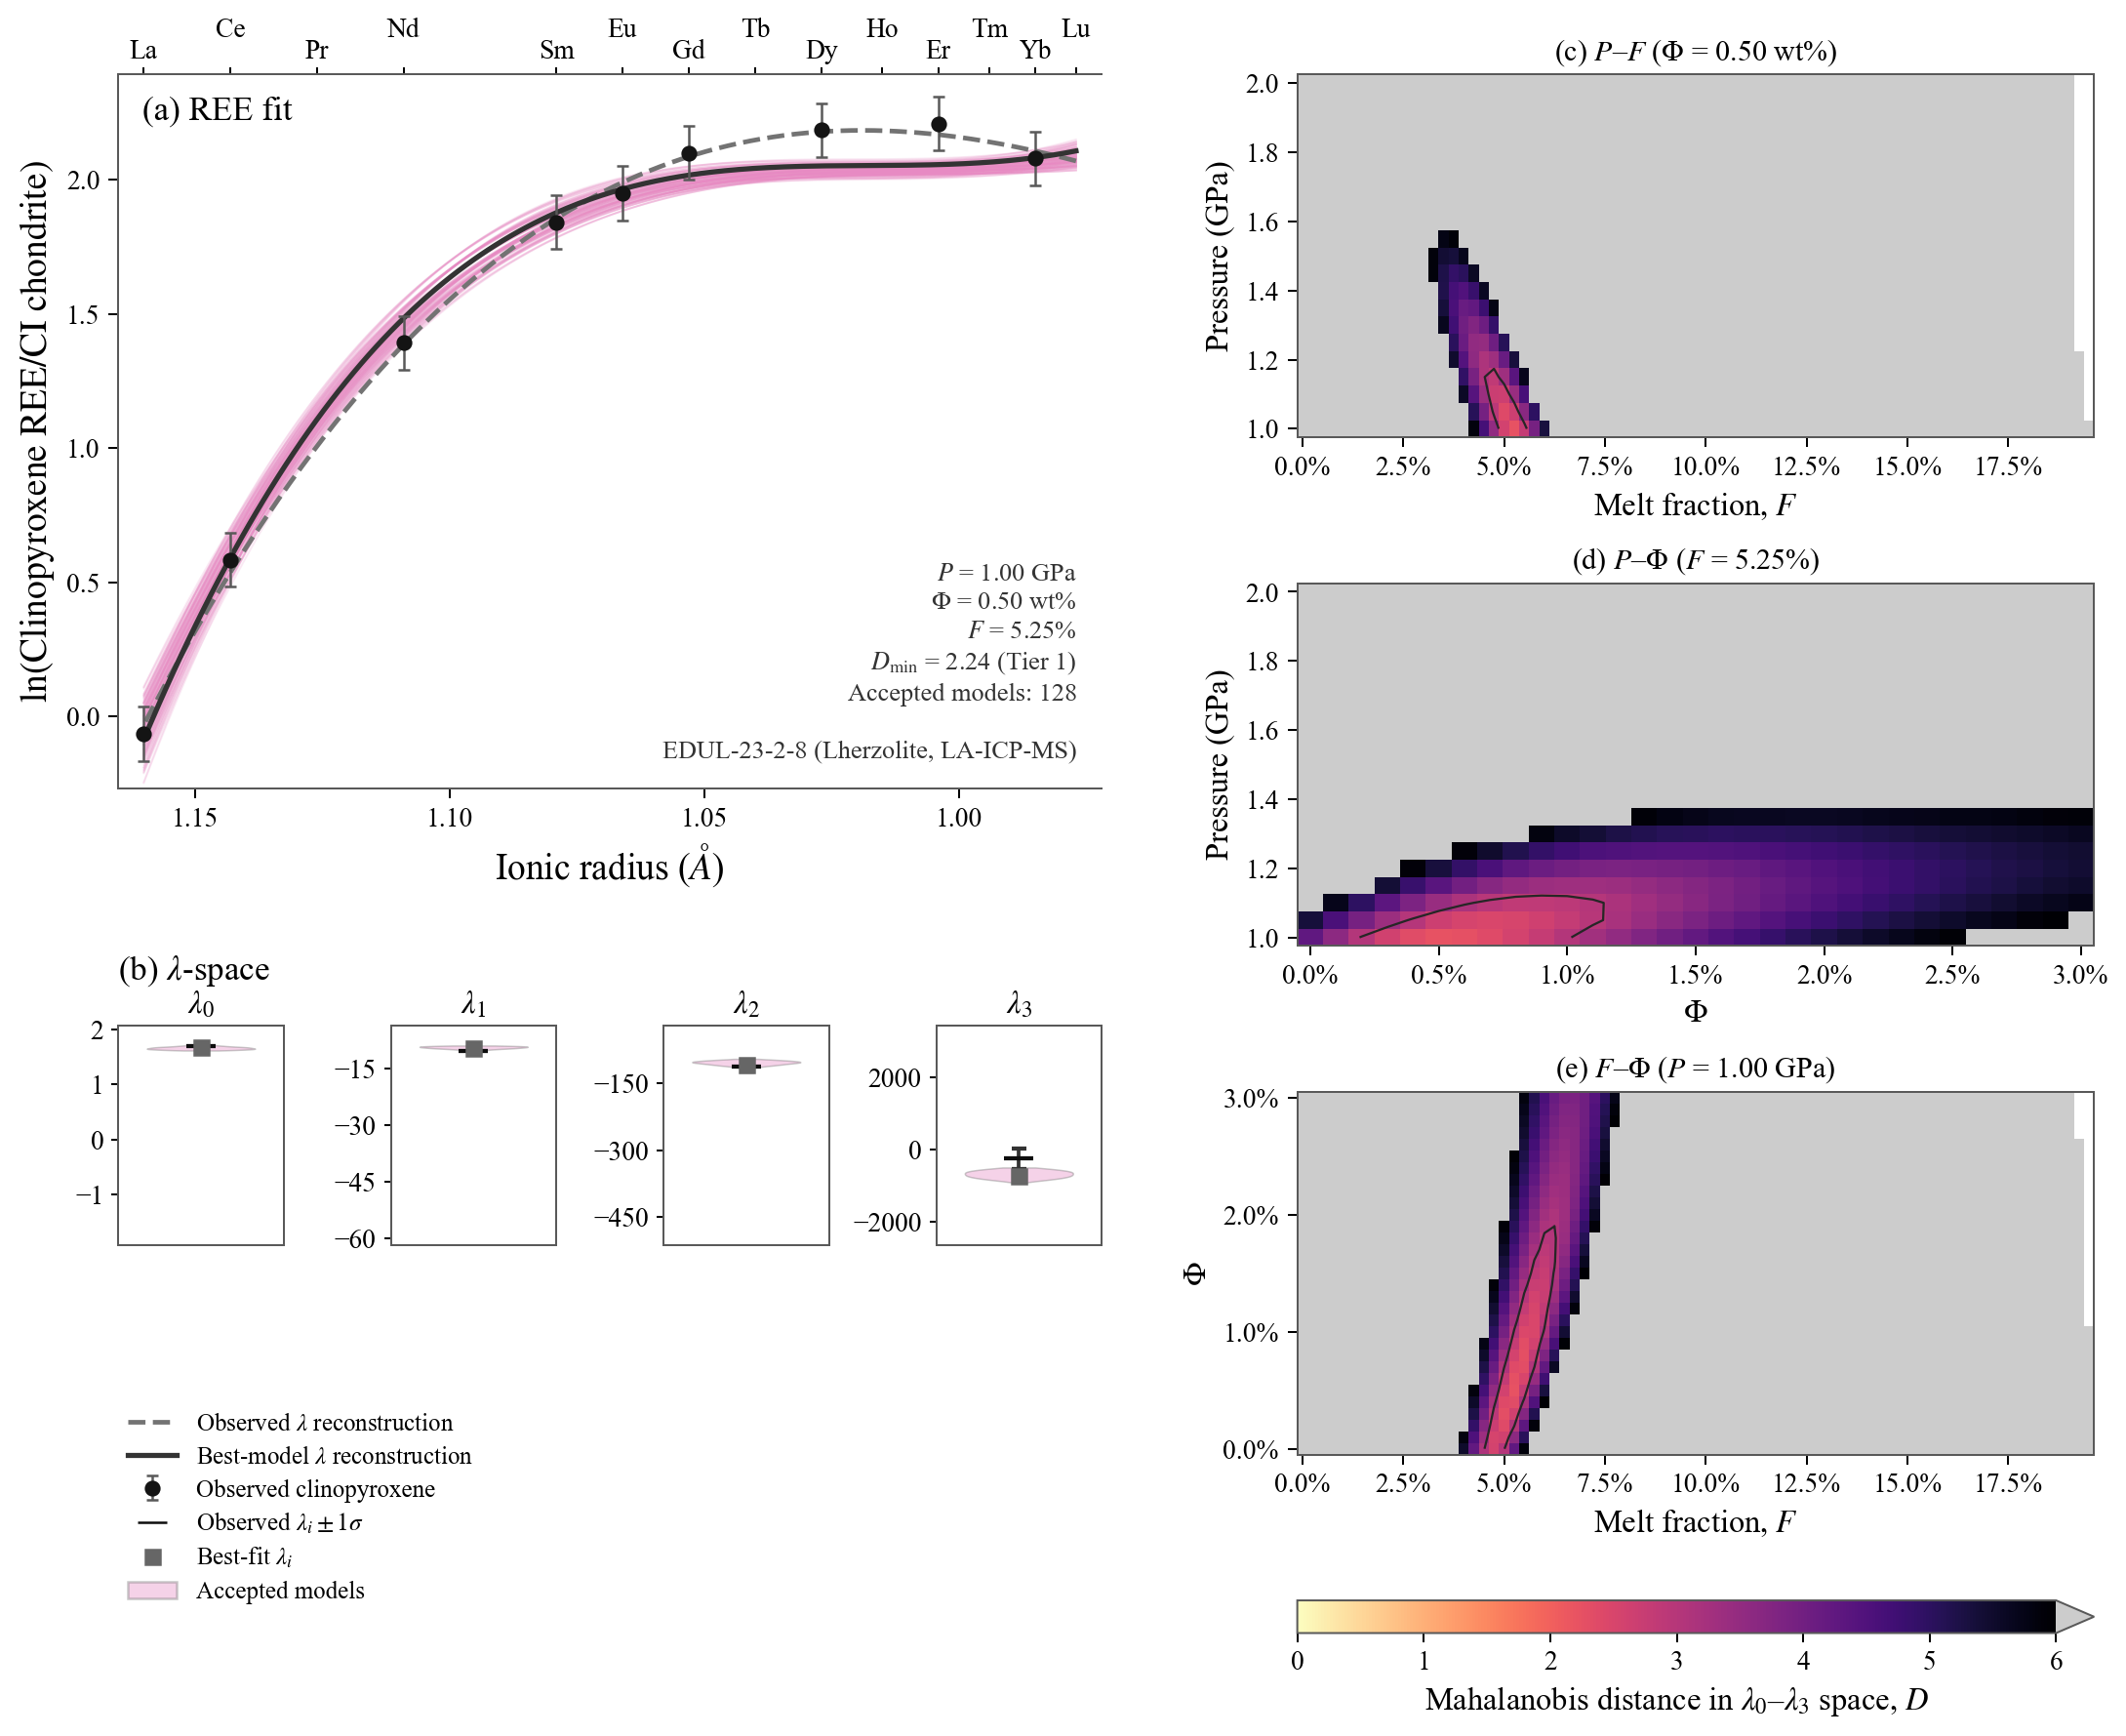

EDUL-23-2-8: P = 1.00 GPa, Phi = 0.50 wt%, F = 5.25%, D_min = 2.24 (Tier 1) | 128 accepted models: P 1.00-1.20 GPa, Phi 0.0-1.9 wt%, F 4.00-6.25%


In [11]:
# Figures 5.3 and 5.4
FONT = dict(panel=14, axis=15, ticks=11, violin=11, legend=10, info=10.5, ree=11)
D_VMAX = D_BROAD


def plot_sample_inversion(name):
    s = warren[warren.Sample.map(norm_name).eq(norm_name(name))].iloc[0]
    proj, z = projected_lambda(s.analysis_id), grid_library.assign(D=mahalanobis(s.analysis_id))
    best = int(np.argmin(z.D))
    b = z.iloc[best]
    tier = fit_tier(b.D)
    threshold = FIT_CUTOFF.get(tier, D_CRIT)
    acc = np.flatnonzero(z.D <= threshold)
    a = z.iloc[acc]
    with plt.rc_context(THESIS_RC):
        fig = plt.figure(figsize=(12.5, 10.5), dpi=180)
        outer = fig.add_gridspec(1, 2, width_ratios=[1.16, 0.94], left=0.07, right=0.97, bottom=0.10, top=0.945, wspace=0.22)
        left = outer[0].subgridspec(3, 1, height_ratios=[3.10, 1.30, 1.0], hspace=0.38)
        right = outer[1].subgridspec(4, 1, height_ratios=[1, 1, 1, 0.09], hspace=0.52)
        ax = fig.add_subplot(left[0])
        block = left[1].subgridspec(2, 1, height_ratios=[0.25, 1], hspace=0.18)
        head = fig.add_subplot(block[0])
        head.axis("off")
        head.text(0, 0.55, r"(b) $\lambda$-space", transform=head.transAxes, va="center", fontsize=FONT["panel"])
        mini = [fig.add_subplot(block[1].subgridspec(1, DEGREE + 1, wspace=0.65)[0, i]) for i in range(DEGREE + 1)]
        info = fig.add_subplot(left[2])
        info.axis("off")
        maps = [fig.add_subplot(right[i]) for i in range(3)]

        show = acc if len(acc) <= 220 else np.random.default_rng(42).choice(acc, 220, replace=False)
        x_curve = lambda_curve(proj[best])[0]
        if len(show):
            ax.plot(x_curve, full_ree_basis(x_curve) @ proj[show].T, color=ACCEPTED_COLOUR, lw=0.75, alpha=0.18, zorder=1)
        ax.plot(*lambda_curve(s[LAMBDA_TERMS]), "--", lw=1.9, color=".45", label=r"Observed $\lambda$ reconstruction", zorder=2)
        ax.plot(*lambda_curve(proj[best]), "-", lw=2.1, color=".20", label=r"Best-model $\lambda$ reconstruction", zorder=3)
        raw = s[REE].to_numpy(float)
        ok = np.isfinite(raw)
        ax.errorbar(IONIC_RADII[ok], ln_ci(raw)[ok], yerr=sigma_ln(raw)[ok], fmt="o", ms=5.5, color=".08",
                    ecolor=".35", elinewidth=1.0, capsize=2.5, label="Observed clinopyroxene", zorder=5)
        style_ree_axis(ax)
        ax.set_ylim(*limits(ln_ci(raw)[ok], lambda_curve(s[LAMBDA_TERMS])[1], lambda_curve(proj[best])[1], min_span=1))
        ax.set_xlabel(r"Ionic radius ($\AA$)", fontsize=FONT["axis"])
        ax.set_ylabel(LN_LABEL, fontsize=FONT["axis"])
        ax.tick_params(labelsize=FONT["ticks"])
        add_ree_top_axis(ax, fontsize=FONT["ree"])
        ax.text(0.025, 0.97, "(a) REE fit", transform=ax.transAxes, va="top", fontsize=FONT["panel"])
        ax.text(0.975, 0.035, f"$P$ = {b.P_GPa:.2f} GPa\n$\\Phi$ = {100 * b.Phi:.2f} wt%\n$F$ = {100 * b.F:.2f}%\n"
                f"$D_{{\\min}}$ = {b.D:.2f} ({tier})\nAccepted models: {len(acc)}\n\n"
                f"{s.Sample} ({s.lithology_group}, {s.trace_method})", transform=ax.transAxes, ha="right", va="bottom",
                fontsize=FONT["info"], linespacing=1.30, color=".20", zorder=20,
                bbox=dict(boxstyle="round,pad=.4", facecolor="white", edgecolor="none", alpha=0.92))

        errors = np.sqrt(np.diag(FITS[s.analysis_id]["cov"]))
        for i, (m, term) in enumerate(zip(mini, LAMBDA_TERMS)):
            vals = proj[acc, i]
            if len(vals) > 1 and np.std(vals) > 0:
                for body in m.violinplot(vals, positions=[0], widths=0.72, showextrema=False)["bodies"]:
                    body.set(facecolor=ACCEPTED_COLOUR, edgecolor=".45", linewidth=0.6, alpha=0.38)
            if len(vals):
                m.vlines(0, vals.min(), vals.max(), color=ACCEPTED_COLOUR, lw=1)
            m.errorbar(0, s[term], yerr=errors[i], fmt="_", ms=12, mew=1.7, color=".05", ecolor=".2", capsize=3, zorder=5)
            m.plot(0, proj[best, i], "s", ms=6, color=".4", zorder=6)
            m.set(xlim=(-0.55, 0.55), xticks=[], ylim=limits(warren[term]))
            m.set_title(rf"$\lambda_{i}$", fontsize=FONT["violin"] + 2, pad=5)
            m.yaxis.set_major_locator(MaxNLocator(4))
            m.tick_params(axis="y", labelsize=FONT["violin"], length=3, width=0.8, pad=3)
        handles, labels = ax.get_legend_handles_labels()
        extra = [Line2D([], [], marker="_", ls="none", color=".05", markersize=12, label=r"Observed $\lambda_i\pm1\sigma$"),
                 Line2D([], [], marker="s", ls="none", color=".4", markersize=6, label=r"Best-fit $\lambda_i$"),
                 Patch(facecolor=ACCEPTED_COLOUR, edgecolor=".45", alpha=0.38, label="Accepted models")]
        info.legend(handles + extra, labels + [h.get_label() for h in extra], loc="upper left", frameon=False,
                    fontsize=FONT["legend"], bbox_to_anchor=(0, 1), borderaxespad=0, labelspacing=0.4)

        fixed = {"Phi": rf"$\Phi$ = {100 * b.Phi:.2f} wt%", "F": rf"$F$ = {100 * b.F:.2f}%", "P_GPa": rf"$P$ = {b.P_GPa:.2f} GPa"}
        cmap = plt.get_cmap("magma_r").copy()
        cmap.set_over(".80")
        cmap.set_bad("white")
        for sub, (xk, yk, hk, xlabel, ylabel, title) in zip(maps, [
                ("F", "P_GPa", "Phi", "Melt fraction, $F$", "Pressure (GPa)", r"(c) $P$–$F$"),
                ("Phi", "P_GPa", "F", r"$\Phi$", "Pressure (GPa)", r"(d) $P$–$\Phi$"),
                ("F", "Phi", "P_GPa", "Melt fraction, $F$", r"$\Phi$", r"(e) $F$–$\Phi$")]):
            q = z[np.isclose(z[hk], b[hk])].pivot_table(index=yk, columns=xk, values="D", aggfunc="min").sort_index().sort_index(axis=1)
            xx, yy = np.meshgrid(q.columns.to_numpy(float), q.index.to_numpy(float))
            zz = q.to_numpy(float)
            pc = sub.pcolormesh(xx, yy, zz, cmap=cmap, vmin=0, vmax=D_VMAX, shading="nearest")
            if min(zz.shape) >= 2 and np.nanmin(zz) <= threshold <= np.nanmax(zz):
                sub.contour(xx, yy, zz, levels=[threshold], colors=".15", linewidths=0.9)
            sub.set(xlabel=xlabel, ylabel=ylabel)
            sub.set_title(f"{title} ({fixed[hk]})", fontsize=12)
            sub.xaxis.label.set_fontsize(13)
            sub.yaxis.label.set_fontsize(13)
            sub.tick_params(labelsize=FONT["ticks"])
            if xk in ("F", "Phi"):
                sub.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
            if yk == "Phi":
                sub.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
        cb = fig.colorbar(pc, cax=fig.add_subplot(right[3]), orientation="horizontal", extend="max")
        cb.set_label(rf"Mahalanobis distance in $\lambda_0$–$\lambda_{DEGREE}$ space, $D$", fontsize=13)
        cb.ax.tick_params(labelsize=FONT["ticks"])
        for axis in [ax] + maps:
            axis.tick_params(direction="out", length=4, width=0.8)
        save_figure(fig, f"abyssal_inversion_{re.sub('[^A-Za-z0-9_-]', '_', str(s.Sample))}")
    print(f"{s.Sample}: P = {b.P_GPa:.2f} GPa, Phi = {100 * b.Phi:.2f} wt%, F = {100 * b.F:.2f}%, D_min = {b.D:.2f} ({tier}) | "
          f"{len(acc)} accepted models: P {a.P_GPa.min():.2f}-{a.P_GPa.max():.2f} GPa, Phi {100 * a.Phi.min():.1f}-"
          f"{100 * a.Phi.max():.1f} wt%, F {100 * a.F.min():.2f}-{100 * a.F.max():.2f}%")


for name in DETAILED_SAMPLES:
    plot_sample_inversion(name)

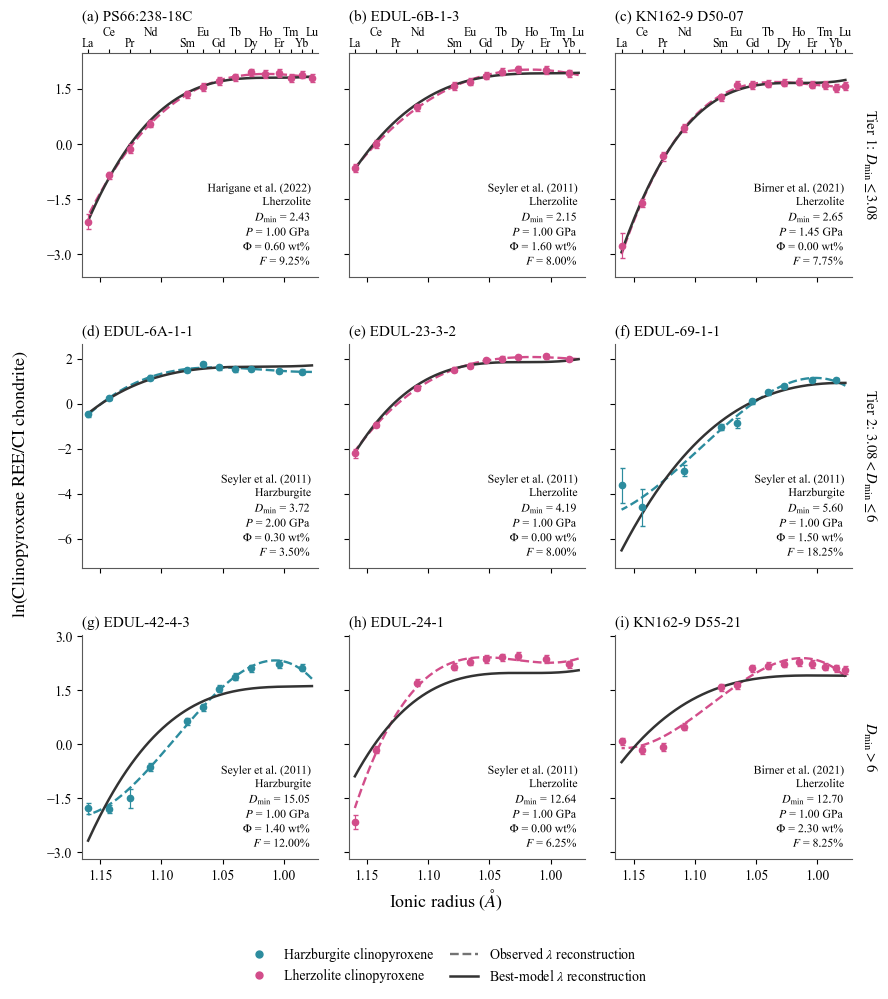

In [12]:
# Figure 5.5
res, samples = pop_res.set_index("analysis_id"), warren.set_index("analysis_id", drop=False)
n_rows = len(EXAMPLES)
ylims = []
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(n_rows, 3, figsize=(9.0, 3.0 * n_rows + 1.4), sharex=True, sharey="row")
    fig.subplots_adjust(left=0.095, right=0.95, top=0.915, bottom=0.14, wspace=0.13, hspace=0.30)
    for k, (ax, aid) in enumerate(zip(axes.flat, [a for ids in EXAMPLES.values() for a in ids])):
        row, col = divmod(k, 3)
        s, r = samples.loc[aid], res.loc[aid]
        colour = LITH_COLOUR[s.lithology_group]
        raw = s[REE].to_numpy(float)
        ok = np.isfinite(raw)
        y, err = ln_ci(raw), sigma_ln(raw)
        model_curve = lambda_curve(projected_lambda(aid)[int(r.best_model)])
        observed_curve = lambda_curve(s[LAMBDA_TERMS])
        ax.plot(*observed_curve, color=colour, ls="--", lw=1.7, zorder=3)
        ax.plot(*model_curve, color=".20", lw=1.8, zorder=4)
        ax.errorbar(IONIC_RADII[ok], y[ok], yerr=err[ok], fmt="o", ms=4.5, color=colour, ecolor=colour,
                    elinewidth=0.85, capsize=1.8, zorder=6)
        ylims.append(limits(y[ok] - err[ok], y[ok] + err[ok], observed_curve[1], model_curve[1], pad=0.10, min_span=1))
        style_ree_axis(ax)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.tick_params(length=3.5, width=0.8, labelsize=10, labelbottom=row == n_rows - 1, labelleft=col == 0)
        if row == 0:
            add_ree_top_axis(ax, fontsize=8.5, low_offset=2, high_offset=10)
        ax.set_title(f"({string.ascii_lowercase[k]}) {s.Sample}", loc="left", fontsize=11, pad=23 if row == 0 else 6)
        ax.text(0.97, 0.04, f"{s.Study}\n{s.lithology_group}\n$D_{{\\min}}$ = {r.D_min:.2f}\n$P$ = {r.P_best:.2f} GPa\n"
                f"$\\Phi$ = {100 * r.Phi_best:.2f} wt%\n$F$ = {100 * r.F_best:.2f}%", transform=ax.transAxes, ha="right",
                va="bottom", fontsize=8.5, linespacing=1.15, color="black", zorder=10,
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    for row, tier in enumerate(EXAMPLES):
        for ax in axes[row]:
            ax.set_ylim(min(l[0] for l in ylims[3 * row:3 * row + 3]), max(l[1] for l in ylims[3 * row:3 * row + 3]))
        axes[row, -1].text(1.04, 0.5, (f"{tier}: " if tier in FIT_CUTOFF else "") + FIT_LABEL[tier],
                           transform=axes[row, -1].transAxes, rotation=-90, ha="left", va="center", fontsize=10.5)
    handles = ([Line2D([], [], marker="o", ls="", color=LITH_COLOUR[l], markersize=5, label=f"{l} clinopyroxene") for l in LITHS]
               + [Line2D([], [], color=".45", ls="--", lw=1.7, label=r"Observed $\lambda$ reconstruction"),
                  Line2D([], [], color=".20", lw=1.8, label=r"Best-model $\lambda$ reconstruction")])
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.008), ncol=2, frameon=False, fontsize=10,
               columnspacing=1.2, handlelength=2.0)
    fig.supxlabel(r"Ionic radius ($\AA$)", y=0.088, fontsize=13)
    fig.supylabel(LN_LABEL, x=0.015, fontsize=13)
    save_figure(fig, "abyssal_example_fits_by_tier_LAICPMS")

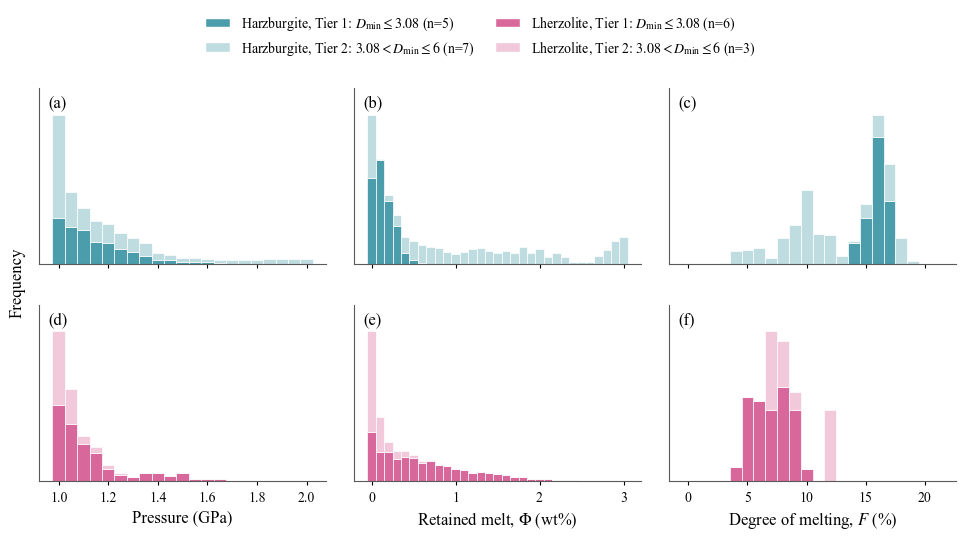

In [13]:
# Figure 5.6
HIST_PANELS = [("P", np.arange(P_MIN_GPA - .025, grid_library.P_GPa.max() + .075, .05), "Pressure (GPa)", 1),
               ("Phi", np.arange(-.0005, grid_library.Phi.max() + .0015, .001), r"Retained melt, $\Phi$ (wt%)", 100),
               ("F", np.arange(-.005, F_LIMIT + .015, .01), r"Degree of melting, $F$ (%)", 100)]
STACK = tuple(FIT_CUTOFF)
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(2, 3, figsize=(9.8, 5.7), sharex="col")
    fig.subplots_adjust(left=.05, right=.985, top=.84, bottom=.15, wspace=.10, hspace=.23)
    handles = []
    for row, lith in enumerate(LITHS):
        colour = LITH_COLOUR[lith]
        counts = pop_res[pop_res.Lithology.eq(lith)].fit_tier.value_counts()
        handles += [Patch(facecolor=to_rgba(colour, FIT_ALPHA[t]), edgecolor="white",
                          label=f"{lith}, {t}: {FIT_LABEL[t]} (n={counts.get(t, 0)})") for t in STACK]
        layers = [hist_models[hist_models.Lithology.eq(lith) & hist_models.fit_tier.eq(t)] for t in STACK]
        for col, (key, bins, label, mult) in enumerate(HIST_PANELS):
            ax = axes[row, col]
            ax.hist([g[key].to_numpy(float) * mult for g in layers], bins=bins * mult,
                    weights=[g.weight.to_numpy(float) for g in layers], stacked=True, histtype="barstacked",
                    color=[to_rgba(colour, FIT_ALPHA[t]) for t in STACK], edgecolor="white", linewidth=.5)
            ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
            if row == 1:
                ax.set_xlabel(label, fontsize=12)
            ax.text(.03, .96, f"({string.ascii_lowercase[row * 3 + col]})", transform=ax.transAxes, va="top", fontsize=12)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=10, length=3)
            ax.tick_params(axis="y", left=False, labelleft=False)
    fig.supylabel("Frequency", fontsize=12)
    fig.legend(handles=handles, ncol=2, loc="upper center", bbox_to_anchor=(.5, .99), frameon=False, fontsize=10,
               columnspacing=1.4, handlelength=1.8)
    save_figure(fig, "abyssal_population_histograms_LAICPMS_fit_tiers_DMM")

,P_best,Phi_best,F_best
Lithology,,,
Harzburgite,1.0,0.003,0.15875
Lherzolite,1.0,0.000,0.07750


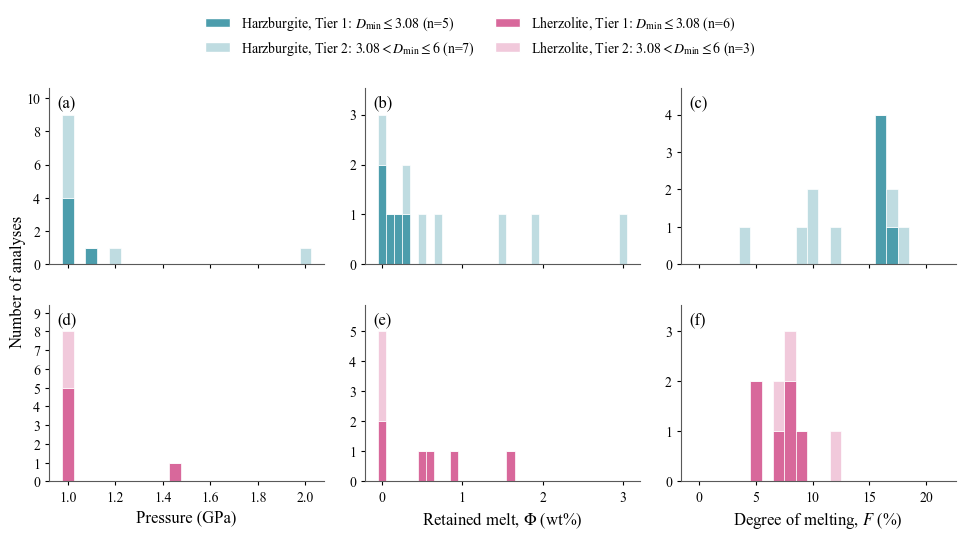

In [15]:
# Figure 5.6 alternative: best-fitting model of each analysis
BEST = {"P": "P_best", "Phi": "Phi_best", "F": "F_best"}
fitted = pop_res[pop_res.fit_tier.isin(STACK)]
display(fitted.groupby("Lithology")[list(BEST.values())].median())
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(2, 3, figsize=(9.8, 5.7), sharex="col")
    fig.subplots_adjust(left=.06, right=.985, top=.84, bottom=.15, wspace=.15, hspace=.23)
    handles = []
    for row, lith in enumerate(LITHS):
        colour = LITH_COLOUR[lith]
        counts = fitted[fitted.Lithology.eq(lith)].fit_tier.value_counts()
        handles += [Patch(facecolor=to_rgba(colour, FIT_ALPHA[t]), edgecolor="white",
                          label=f"{lith}, {t}: {FIT_LABEL[t]} (n={counts.get(t, 0)})") for t in STACK]
        layers = [fitted[fitted.Lithology.eq(lith) & fitted.fit_tier.eq(t)] for t in STACK]
        for col, (key, bins, label, mult) in enumerate(HIST_PANELS):
            ax = axes[row, col]
            ax.hist([g[BEST[key]].to_numpy(float) * mult for g in layers], bins=bins * mult, stacked=True,
                    histtype="barstacked", color=[to_rgba(colour, FIT_ALPHA[t]) for t in STACK],
                    edgecolor="white", linewidth=.5)
            ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))
            if row == 1:
                ax.set_xlabel(label, fontsize=12)
            ax.text(.03, .96, f"({string.ascii_lowercase[row * 3 + col]})", transform=ax.transAxes, va="top", fontsize=12)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=10, length=3)
    fig.supylabel("Number of analyses", fontsize=12)
    fig.legend(handles=handles, ncol=2, loc="upper center", bbox_to_anchor=(.5, .99), frameon=False, fontsize=10,
               columnspacing=1.4, handlelength=1.8)
    save_figure(fig, "abyssal_population_histograms_best_fit_LAICPMS_DMM")

In [14]:
# Numbers quoted in Chapter 5
def wquantile(x, w, q=(0.16, 0.50, 0.84)):
    o = np.argsort(x)
    x, w = np.asarray(x, float)[o], np.asarray(w, float)[o]
    return np.interp(q, (np.cumsum(w) - 0.5 * w) / w.sum(), x)


measured = warren[REE].notna()
display(pd.DataFrame({"LA-ICP-MS": {"median n REE": measured.sum(axis=1).median(), "with Lu": int(measured.Lu.sum()),
                                    **{f"missing {e}": int((~measured[e]).sum()) for e in REE}}}).T)

display(pop_res.groupby("Lithology").D_min.describe(percentiles=[0.25, 0.5, 0.75]).round(2))

rows = []
for t in FIT_TIERS:
    for lith in (*LITHS, "All"):
        g = pop_res[pop_res.Lithology.eq(lith)] if lith != "All" else pop_res
        r = g[g.fit_tier.eq(t)]
        a = hist_models[hist_models.analysis_id.isin(r.analysis_id)]
        row = {"Fit tier": t, "Lithology": lith, "n": len(r), "% of lithology": round(100 * len(r) / len(g), 1),
               "D_min range": f"{r.D_min.min():.2f}–{r.D_min.max():.2f}" if len(r) else "",
               "best P at 1.0 GPa": int(np.isclose(r.P_best, grid_library.P_GPa.min()).sum()),
               "best Φ at 3.0 wt%": int(np.isclose(r.Phi_best, grid_library.Phi.max()).sum()),
               "accepted P range": f"{a.P.min():.2f}–{a.P.max():.2f}" if len(a) else ""}
        for c, k, u in (("P", 1, "P (GPa)"), ("Phi", 100, "Φ (wt%)"), ("F", 100, "F (%)")):
            lo, med, hi = wquantile(a[c], a.weight) * k if len(a) else (np.nan,) * 3
            row[u] = f"{med:.2f} ({lo:.2f}–{hi:.2f})" if len(a) else ""
        rows.append(row)
display(pd.DataFrame(rows).set_index(["Fit tier", "Lithology"]))
print(f"Model lambda3 max: {grid_library.lambda3.max():.0f}; natural analyses above it: "
      f"{(warren.lambda3 > grid_library.lambda3.max()).sum()} of {len(warren)} (max {warren.lambda3.max():.0f})")

,median n REE,with Lu,missing La,missing Ce,missing Pr,missing Nd,missing Sm,missing Eu,missing Gd,missing Tb,missing Dy,missing Ho,missing Er,missing Tm,missing Yb,missing Lu
LA-ICP-MS,13.0,24.0,3.0,2.0,20.0,0.0,0.0,0.0,0.0,4.0,0.0,19.0,0.0,19.0,0.0,27.0


,count,mean,std,min,25%,50%,75%,max
Lithology,,,,,,,,
Harzburgite,25.0,7.24,4.04,1.49,4.93,6.10,9.07,15.44
Lherzolite,26.0,7.38,3.81,2.15,4.54,7.43,9.83,15.13


n  % of lithology D_min range  best P at 1.0 GPa  \
Fit tier      Lithology                                                        
Tier 1        Harzburgite   5            20.0   1.49–2.89                  4   
              Lherzolite    6            23.1   2.15–2.65                  5   
              All          11            21.6   1.49–2.89                  9   
Tier 2        Harzburgite   7            28.0   3.72–5.97                  5   
              Lherzolite    3            11.5   4.19–5.68                  3   
              All          10            19.6   3.72–5.97                  8   
Outside tiers Harzburgite  13            52.0  6.10–15.44                 10   
              Lherzolite   17            65.4  6.40–15.13                 16   
              All          30            58.8  6.10–15.44                 26   

                           best Φ at 3.0 wt% accepted P range  \
Fit tier      Lithology                                         
Tier 1        Harzburgite                  0        1.00–1.75   
              Lherzolite                   0        1.00–1.65   
              All                          0        1.00–1.75   
Tier 2        Harzburgite                  1        1.00–2.00   
              Lherzolite                   0        1.00–1.30   
              All                          1        1.00–2.00   
Outside tiers Harzburgite                  4                    
              Lherzolite                   2                    
              All                          6                    

                                    P (GPa)           Φ (wt%)  \
Fit tier      Lithology                                         
Tier 1        Harzburgite  1.10 (1.00–1.30)  0.10 (0.00–0.30)   
              Lherzolite   1.05 (1.00–1.30)  0.50 (0.10–1.20)   
              All          1.10 (1.00–1.30)  0.20 (0.00–0.90)   
Tier 2        Harzburgite  1.10 (1.00–1.50)  1.22 (0.20–2.70)   
              Lherzolite   1.00 (1.00–1.10)  0.00 (0.00–0.20)   
              All          1.05 (1.00–1.35)  0.60 (0.00–2.20)   
Outside tiers Harzburgite                                       
              Lherzolite                                        
              All                                               

                                         F (%)  
Fit tier      Lithology                         
Tier 1        Harzburgite  16.00 (15.00–16.50)  
              Lherzolite      7.00 (5.25–8.50)  
              All            9.00 (5.65–16.25)  
Tier 2        Harzburgite   10.25 (7.99–16.50)  
              Lherzolite     8.00 (6.86–11.75)  
              All           10.00 (7.00–15.75)  
Outside tiers Harzburgite                       
              Lherzolite                        
              All

Model lambda3 max: -43; natural analyses above it: 23 of 51 (max 3016)
